# F_lick_beh_session_comparison.ipynb

## Purpose
Plot lick statistics against behavioral metrics, session by session.  
Each scatter plot shows one dot per session; sessions are color-coded by animal.  
Pearson and Spearman correlations (with p-values) are annotated on each panel.

**Lick statistics** come from the per-animal `lick_train_stats_video_True.pkl` files  
produced by `lick_train_analysis.ipynb`.

**Behavioral metrics** come from `combined_beh_sessions.pkl`  
produced by the figure-preparation pipeline used in `F_behavior_w_FP.ipynb`.

## Prerequisites
- `data/results/manuscript/prep/spontlicks/video/{animal_id}_lick_train_stats_video_True.pkl`
- `data/results/manuscript/prep/combined_session_tbl/combined_beh_sessions.pkl`

## Imports

In [1]:
import os
import pathlib
import sys
import glob
import pickle
import warnings

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

warnings.filterwarnings('ignore')

# Resolve beh_ephys_analysis root so utils imports work regardless of cwd
try:
    _here = pathlib.Path(__file__).resolve().parent
except NameError:
    try:
        _here = pathlib.Path(__vsc_ipynb_file__).resolve().parent
    except NameError:
        _here = pathlib.Path(os.getcwd())

_beh_ephys_root = str((_here / '../..').resolve())
if _beh_ephys_root not in sys.path:
    sys.path.insert(0, _beh_ephys_root)

from utils.capsule_migration import capsule_directories, CAPSULE_ROOT
from utils.combine_tools import apply_qc

import json

capsule_dirs = capsule_directories()
%matplotlib inline

## Directory setup

In [2]:
# Input directories
spontlicks_dir = os.path.join(
    str(capsule_dirs['manuscript_fig_prep_dir']), 'spontlicks', 'video'
)
beh_pkl_path = os.path.join(
    str(capsule_dirs['manuscript_fig_prep_dir']), 'combined_session_tbl', 'combined_beh_sessions.pkl'
)

# Output directory
target_folder = os.path.join(str(capsule_dirs['manuscript_fig_dir']), 'F_lick_beh_session_comparison')
os.makedirs(target_folder, exist_ok=True)

print('Lick stats dir :', spontlicks_dir)
print('Behavior pkl   :', beh_pkl_path)
print('Output dir     :', target_folder)

Lick stats dir : /root/capsule/scratch/result/manuscript/prep/spontlicks/video
Behavior pkl   : /root/capsule/scratch/result/manuscript/prep/combined_session_tbl/combined_beh_sessions.pkl
Output dir     : /root/capsule/scratch/result/manuscript/figures/F_lick_beh_session_comparison


## Load lick statistics (session level)

Concatenate all per-animal `lick_train_stats_video_True.pkl` files into a single  
session-level DataFrame.  Each row = one session.

In [3]:
lick_pkl_files = sorted(glob.glob(os.path.join(spontlicks_dir, '*_lick_train_stats_video_True.pkl')))
print(f'Found {len(lick_pkl_files)} animal lick stats files')

lick_rows = []
for pkl_path in lick_pkl_files:
    with open(pkl_path, 'rb') as f:
        res = pickle.load(f)

    n = len(res['session_ids'])
    for i in range(n):
        row = {
            'session_id'                  : res['session_ids'][i],
            'animal_id'                   : str(res['animal_id']),
            # R/L lick ratios
            'rl_ratio_out'                : res['rl_ratio_out'][i],
            'rl_ratio_in'                 : res['rl_ratio_in'][i],
            'rl_ratio_outvsin'            : res['rl_ratio_outvsin'][i],
            'rl_ratio_choice'             : res['rl_ratio_choice'][i],
            'rl_ratio_in_reward_choices'  : res['rl_ratio_in_reward_choices'][i],
            # Fraction of licks that are in-trial
            'in_out_ratio'                : res['in_out_ratio'][i],
            # Mean lick train lengths per lick type
            'lick_len_all_mean'           : res['all_licks']['len_mean'][i],
            'lick_len_in_rwd_mean'        : res['in_trial_rwd_licks']['len_mean'][i],
            'lick_len_in_nrwd_mean'       : res['in_trial_no_rwd_licks']['len_mean'][i],
            'lick_len_out_mean'           : res['out_of_trial_licks']['len_mean'][i],
            # Lick train counts
            'lick_count_all'              : res['all_licks']['count'][i],
            'lick_count_in_rwd'           : res['in_trial_rwd_licks']['count'][i],
            'lick_count_in_nrwd'          : res['in_trial_no_rwd_licks']['count'][i],
            'lick_count_out'              : res['out_of_trial_licks']['count'][i],
        }
        lick_rows.append(row)

lick_df = pd.DataFrame(lick_rows)
print(f'Session-level lick DataFrame: {lick_df.shape}')
lick_df.head(3)

Found 41 animal lick stats files
Session-level lick DataFrame: (384, 16)


,session_id,animal_id,rl_ratio_out,rl_ratio_in,rl_ratio_outvsin,rl_ratio_choice,rl_ratio_in_reward_choices,in_out_ratio,lick_len_all_mean,lick_len_in_rwd_mean,lick_len_in_nrwd_mean,lick_len_out_mean,lick_count_all,lick_count_in_rwd,lick_count_in_nrwd,lick_count_out
0,behavior_669489_2023-06-24_14-56-01,669489,-0.233202,0.370892,-0.604094,0.300668,0.422594,0.674487,0.976232,1.841310,0.613129,0.301261,341,129,101,111
1,behavior_669489_2023-06-26_16-23-02,669489,-0.624309,-0.180583,-0.443727,-0.140115,-0.143860,0.606264,0.834523,1.688963,0.485426,0.257415,447,163,108,176
2,behavior_669489_2023-06-27_14-20-19,669489,-0.217082,0.184426,-0.401508,0.197628,0.201465,0.669251,0.840375,1.620627,0.413349,0.289656,387,150,109,128


## Load behavioral metrics and apply QC filter

Applying bounds for session_len: [90, None]
 - session_len: 345 -> 344 units passed
Applying bounds for p_sw_L: [0.04, None]
 - p_sw_L: 344 -> 341 units passed
Applying bounds for aN: [0.15, None]
 - aN: 341 -> 278 units passed
Applying bounds for diff_1: [0, None]
 - diff_1: 278 -> 277 units passed
Applying bounds for bias: [-1.25, 1.25]
 - bias: 277 -> 259 units passed
Number of opto rows after filtering: 259
Number of non-opto rows after filtering: 259
All sessions          : 345
QC-passed sessions    : 259


,aN,aP,aF,beta,bias,session_id,p_sw,p_sw_L,p_st_w,finish_rate,...,ani_id,probe,session,sw_nrwd_rwd,sw_bias,lat_bias_abs,var_lat_bias_abs,lick_bias,p_sw_L-W,selected_qc_only
0,0.289967,0.688666,0.344759,4.309723,0.422339,behavior_716325_2024-05-29_10-33-32,0.072398,0.160494,0.985612,0.824627,...,716325,2,behavior_716325_2024-05-29_10-33-32,0.146105,0.282242,0.262551,0.364002,False,0.146105,True
1,0.208647,0.792320,0.084670,4.217211,-1.052228,behavior_751004_2024-12-22_13-09-17,0.053371,0.123967,0.982979,0.919897,...,751004,2,behavior_751004_2024-12-22_13-09-17,0.106946,-0.552237,0.368874,0.502588,False,0.106946,True
2,0.308987,0.834723,0.092177,4.256940,-0.588881,behavior_751769_2025-01-16_11-32-05,0.078125,0.154839,0.978070,0.827214,...,751769,2,behavior_751769_2025-01-16_11-32-05,0.132909,-0.307051,0.199903,0.537739,False,0.132909,True


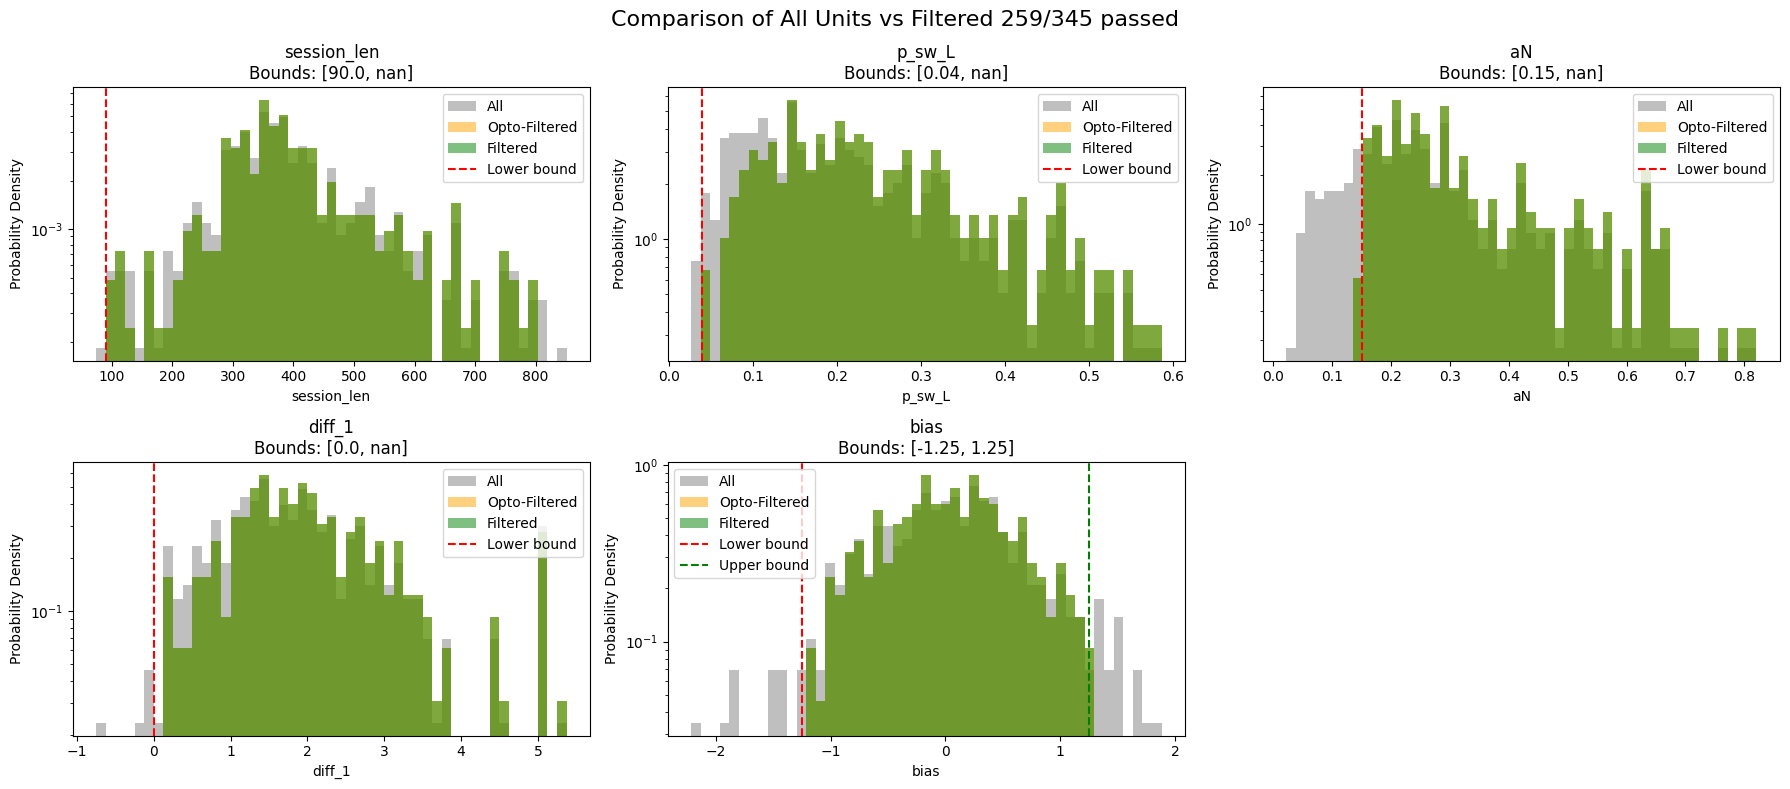

In [4]:
with open(beh_pkl_path, 'rb') as f:
    combined_session_tbl = pickle.load(f)

# Mirror the p_st_w / diff_1 clipping used in F_behavior_w_FP
combined_session_tbl.loc[combined_session_tbl['p_st_w'] == 1, 'diff_1'] = 5
combined_session_tbl['p_sw_L-W'] = (
    combined_session_tbl['p_sw_L'] - (1 - combined_session_tbl['p_st_w'])
)

# Apply the same behavioral QC used in F_behavior_w_FP
beh_criteria_path = os.path.join(
    CAPSULE_ROOT, 'code', 'beh_ephys_analysis',
    'session_combine', 'metrics', 'beh_only.json'
)
with open(beh_criteria_path, 'r') as f:
    beh_constraints = json.load(f)

combined_session_tbl_filtered, combined_session_tbl_all, _, _ = apply_qc(
    combined_session_tbl, beh_constraints
)

print(f'All sessions          : {len(combined_session_tbl_all)}')
print(f'QC-passed sessions    : {len(combined_session_tbl_filtered)}')
combined_session_tbl_filtered.head(3)

## Merge lick stats with behavioral metrics

In [5]:
# Use session_id as the merge key
# lick_df uses the raw session_id strings from the pkl;
# combined_session_tbl uses the 'session_id' column (same format).
merged_df = pd.merge(
    lick_df,
    combined_session_tbl_filtered,
    on='session_id',
    how='inner',
    suffixes=('_lick', '_beh'),
)

# Use animal_id from the lick side (string); overwrite if beh side duplicates
if 'animal_id_beh' in merged_df.columns:
    merged_df.drop(columns=['animal_id_beh'], inplace=True)
if 'animal_id_lick' in merged_df.columns:
    merged_df.rename(columns={'animal_id_lick': 'animal_id'}, inplace=True)

print(f'Merged DataFrame shape: {merged_df.shape}')
print(f'Animals in merged data: {sorted(merged_df["animal_id"].unique())}')
merged_df.head(3)

Merged DataFrame shape: (259, 62)
Animals in merged data: ['669489', '669492', '672850', '699461', '699462', '699472', '701707', '716325', '749472', '749624', '751004', '751181', '751766', '751769', '752014', '754895', '754896', '754897', '758017', '758018', '761038', '763590', '781166', '782394', '784803', '784806', '785956', '791691', 'ZS059', 'ZS060', 'ZS061', 'ZS062']


,session_id,animal_id,rl_ratio_out,rl_ratio_in,rl_ratio_outvsin,rl_ratio_choice,rl_ratio_in_reward_choices,in_out_ratio,lick_len_all_mean,lick_len_in_rwd_mean,...,ani_id,probe,session,sw_nrwd_rwd,sw_bias,lat_bias_abs,var_lat_bias_abs,lick_bias,p_sw_L-W,selected_qc_only
0,behavior_669489_2023-06-24_14-56-01,669489,-0.233202,0.370892,-0.604094,0.300668,0.422594,0.674487,0.976232,1.841310,...,669489,NaN,behavior_669489_2023-06-24_14-56-01,0.093905,0.238844,0.392120,0.046211,False,0.093905,True
1,behavior_669489_2023-06-26_16-23-02,669489,-0.624309,-0.180583,-0.443727,-0.140115,-0.143860,0.606264,0.834523,1.688963,...,669489,NaN,behavior_669489_2023-06-26_16-23-02,0.108772,0.062500,0.268191,1.063552,False,0.108772,True
2,behavior_669489_2023-06-27_14-20-19,669489,-0.217082,0.184426,-0.401508,0.197628,0.201465,0.669251,0.840375,1.620627,...,669489,NaN,behavior_669489_2023-06-27_14-20-19,0.124523,0.281876,0.401869,0.314480,False,0.124523,True


## Define lick and behavior column groups

Edit these lists to add or remove metrics from the scatter plots.

In [6]:
LICK_COLS = [
    # R/L lick bias
    ('rl_ratio_out',               'Spont lick R/L ratio (out-of-trial)'),
    ('rl_ratio_in',                'In-trial lick R/L ratio'),
    ('rl_ratio_outvsin',           'R/L ratio: out − in'),
    ('rl_ratio_choice',            'Choice R/L ratio'),
    ('rl_ratio_in_reward_choices', 'In-trial R/L ratio (rewarded choices)'),
    # Lick engagement
    ('in_out_ratio',               'Fraction in-trial licks'),
    # Train durations
    ('lick_len_all_mean',          'Mean lick train len (all)'),
    ('lick_len_in_rwd_mean',       'Mean lick train len (in-trial, rewarded)'),
    ('lick_len_in_nrwd_mean',      'Mean lick train len (in-trial, unrewarded)'),
    ('lick_len_out_mean',          'Mean lick train len (out-of-trial)'),
]

BEH_COLS = [
    # RL model params
    ('aN',          'α− (neg learning rate)'),
    ('aP',          'α+ (pos learning rate)'),
    ('aF',          'αF (forgetting rate)'),
    ('beta',        'β (inverse temperature)'),
    # Behavioral tendencies
    ('p_st_w',      'P(stay | win)'),
    ('p_sw_L',      'P(switch | loss)'),
    ('p_sw_L-W',    'P(sw|L) − P(sw|W)'),
    ('sw_bias',     'Switch bias'),
    # GLM coefficients
    ('rwd_1',       'GLM reward coeff (lag 1)'),
    ('nrwd_1',      'GLM no-reward coeff (lag 1)'),
    ('sw_nrwd_rwd', 'GLM sw: no-reward − reward'),
    # Lick latency metrics (from beh table)
    ('lick_lat_diff',  'Lick latency diff (L−R)'),
    ('lick_bias',      'Lick bias'),
]

# Filter to columns that actually exist in the merged DataFrame
LICK_COLS = [(c, lbl) for c, lbl in LICK_COLS if c in merged_df.columns]
BEH_COLS  = [(c, lbl) for c, lbl in BEH_COLS  if c in merged_df.columns]

print(f'Lick columns available : {len(LICK_COLS)}')
print(f'Behavior columns available: {len(BEH_COLS)}')

Lick columns available : 10
Behavior columns available: 13


## Helper: scatter plot with correlation annotation

In [7]:
# Build a stable color palette — one color per animal
animals = sorted(merged_df['animal_id'].unique())
palette  = sns.color_palette('tab20', n_colors=len(animals))
ANI_COLOR = {ani: palette[i] for i, ani in enumerate(animals)}


def scatter_lick_vs_beh(
    ax,
    df,
    x_col, x_label,
    y_col, y_label,
    show_regression=True,
):
    """Draw a session-level scatter of y_col vs x_col on ax.

    Colors each point by animal; annotates Pearson r and Spearman ρ.
    """
    valid = df[[x_col, y_col, 'animal_id']].dropna()
    if len(valid) < 3:
        ax.set_visible(False)
        return

    for ani, grp in valid.groupby('animal_id'):
        ax.scatter(
            grp[x_col], grp[y_col],
            # color=ANI_COLOR.get(ani, 'gray'),
            s=20, alpha=0.75, edgecolors='white', linewidths=0.3,
            label=ani,
        )

    if show_regression:
        sns.regplot(
            x=valid[x_col], y=valid[y_col],
            scatter=False, ax=ax,
            line_kws={'color': 'k', 'lw': 1.2},
            ci=95,
        )

    # Pearson
    r_p, p_p = pearsonr(valid[x_col], valid[y_col])
    # Spearman
    r_s, p_s = spearmanr(valid[x_col], valid[y_col])

    color_p = 'red' if p_p < 0.05 else 'gray'
    color_s = 'red' if p_s < 0.05 else 'gray'
    ax.set_title(
        f'r={r_p:.2f} (p={p_p:.2e})  ρ={r_s:.2f} (p={p_s:.2e})\nn={len(valid)}',
        fontsize=7,
        color='red' if p_p < 0.05 or p_s < 0.05 else 'gray',
    )
    ax.set_xlabel(x_label, fontsize=8)
    ax.set_ylabel(y_label, fontsize=8)
    ax.tick_params(labelsize=7)

## Grid plot: each lick metric vs each behavior metric

Rows = lick statistics; columns = behavioral metrics.  
Significant correlations (p < 0.05 for Pearson or Spearman) have red titles.

Saved: /root/capsule/scratch/result/manuscript/figures/F_lick_beh_session_comparison/lick_vs_beh_full_grid.pdf


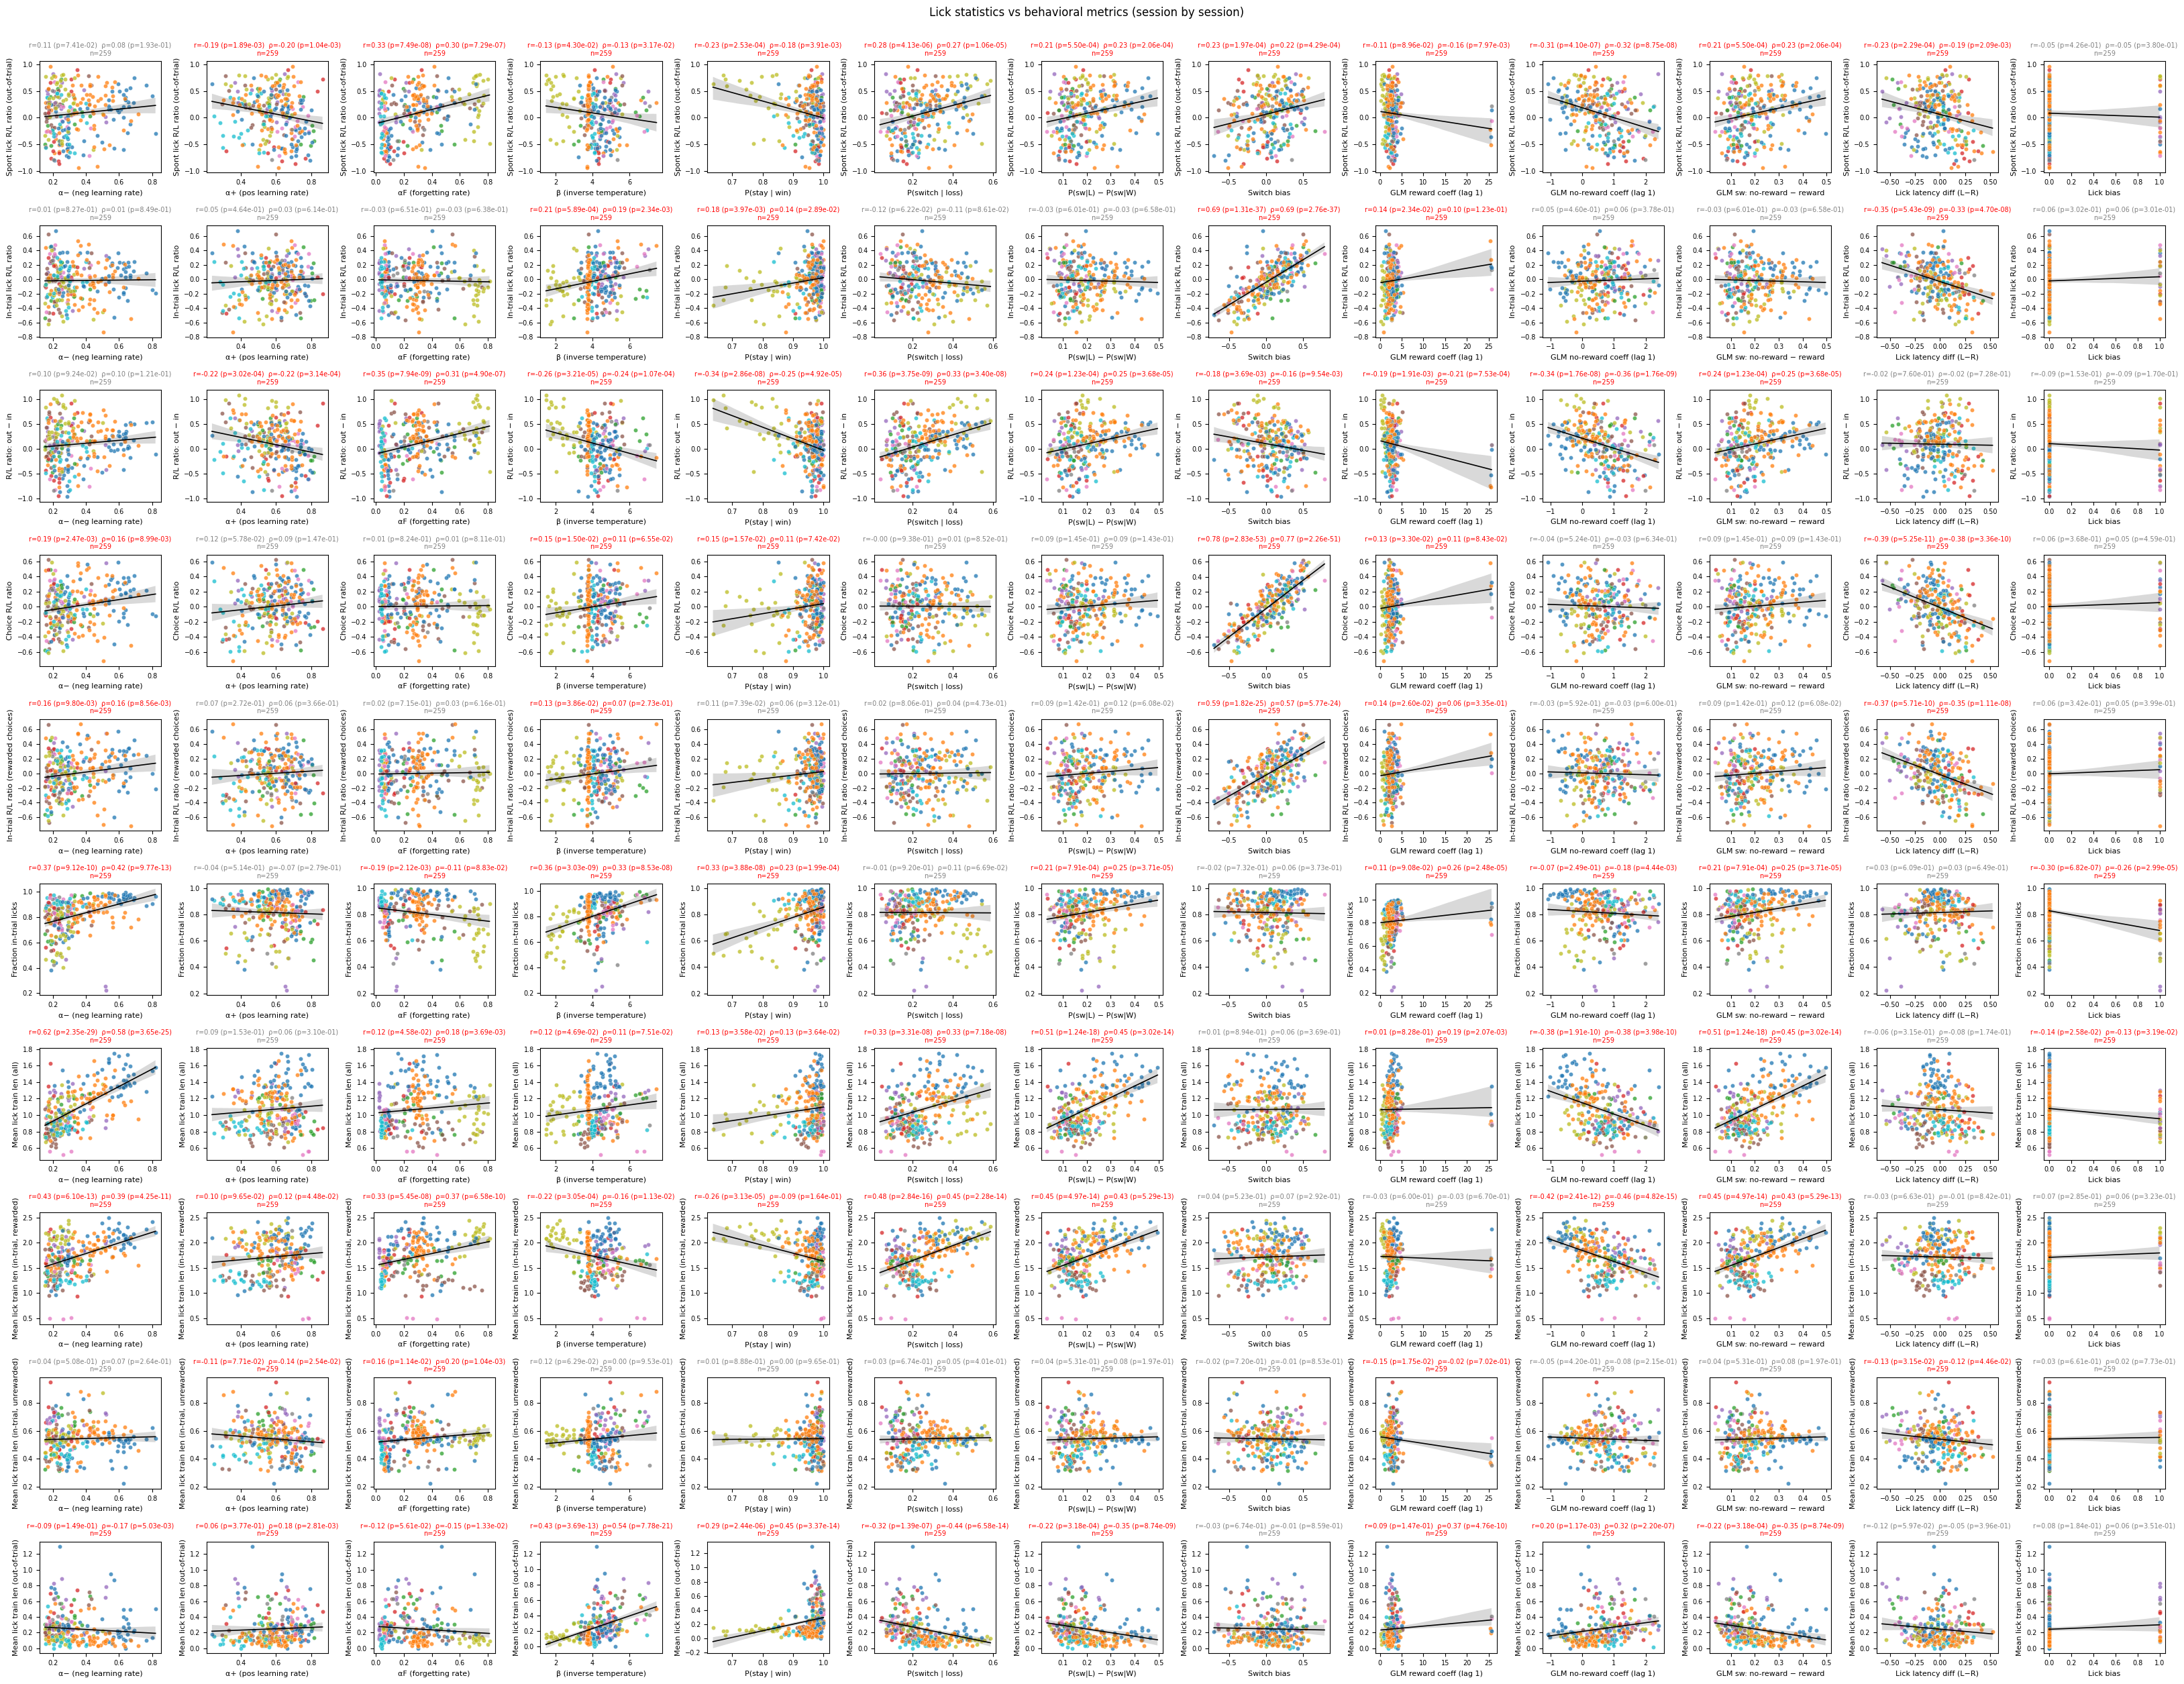

In [8]:
n_lick = len(LICK_COLS)
n_beh  = len(BEH_COLS)

fig, axes = plt.subplots(
    n_lick, n_beh,
    figsize=(2.5 * n_beh, 2.5 * n_lick),
    squeeze=False,
)

for row_i, (lick_col, lick_lbl) in enumerate(LICK_COLS):
    for col_j, (beh_col, beh_lbl) in enumerate(BEH_COLS):
        ax = axes[row_i, col_j]
        scatter_lick_vs_beh(
            ax, merged_df,
            x_col=beh_col,  x_label=beh_lbl,
            y_col=lick_col, y_label=lick_lbl,
        )

plt.suptitle(
    'Lick statistics vs behavioral metrics (session by session)',
    fontsize=12, y=1.002,
)
plt.tight_layout()

out_path = os.path.join(target_folder, 'lick_vs_beh_full_grid.pdf')
fig.savefig(out_path, bbox_inches='tight', dpi=300)
print(f'Saved: {out_path}')
plt.show()

## R/L lick bias vs choice bias — focused scatter

Compares the spontaneous (out-of-trial) lick R/L ratio to the choice-based R/L ratio  
and to the RL model side bias parameter.

Saved: /root/capsule/scratch/result/manuscript/figures/F_lick_beh_session_comparison/rl_lick_bias_vs_choice_bias.pdf


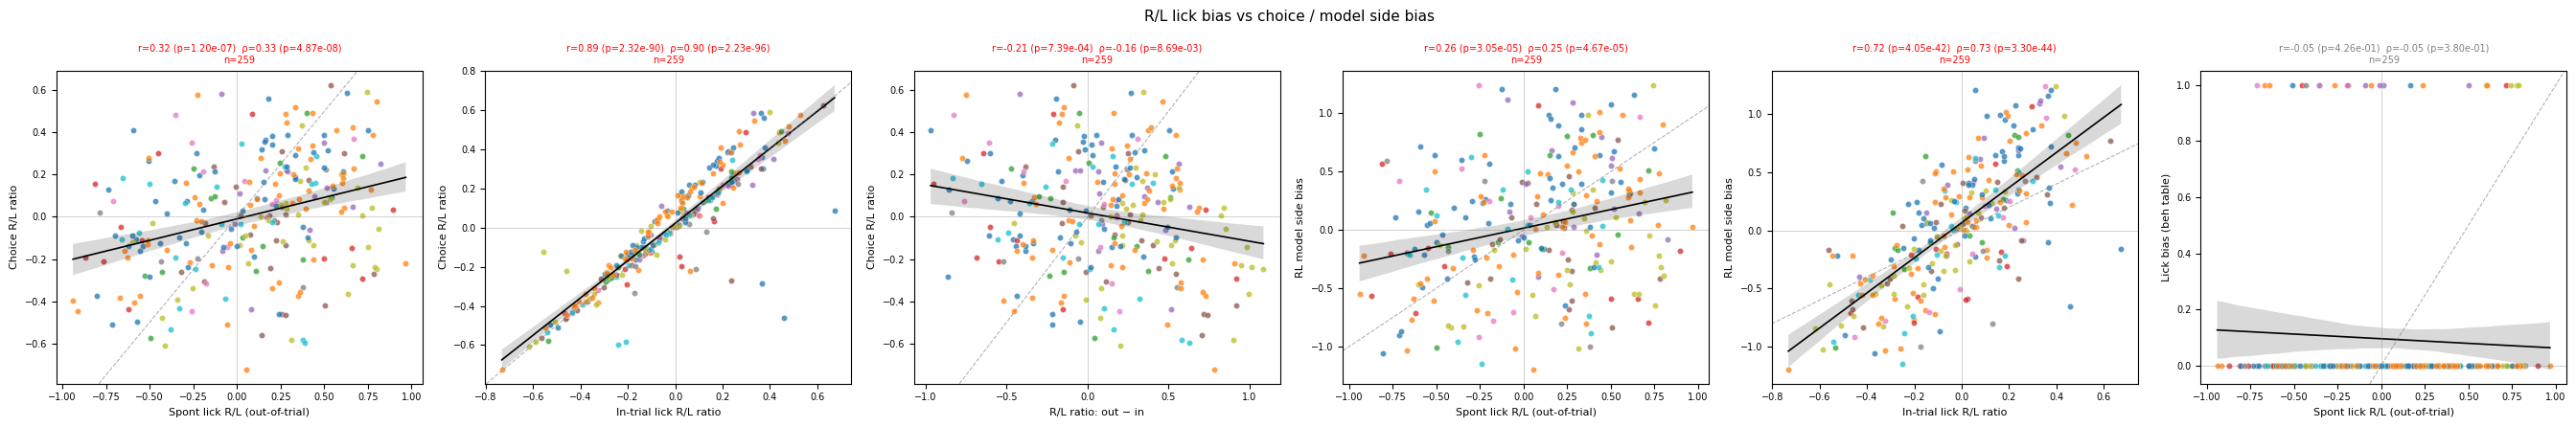

In [9]:
rl_pairs = [
    ('rl_ratio_out',    'Spont lick R/L (out-of-trial)',       'rl_ratio_choice', 'Choice R/L ratio'),
    ('rl_ratio_in',     'In-trial lick R/L ratio',             'rl_ratio_choice', 'Choice R/L ratio'),
    ('rl_ratio_outvsin','R/L ratio: out − in',                 'rl_ratio_choice', 'Choice R/L ratio'),
    ('rl_ratio_out',    'Spont lick R/L (out-of-trial)',       'bias',            'RL model side bias'),
    ('rl_ratio_in',     'In-trial lick R/L ratio',             'bias',            'RL model side bias'),
    ('rl_ratio_out',    'Spont lick R/L (out-of-trial)',       'lick_bias',       'Lick bias (beh table)'),
]

rl_pairs = [(x_c, x_l, y_c, y_l) for x_c, x_l, y_c, y_l in rl_pairs
            if x_c in merged_df.columns and y_c in merged_df.columns]

if rl_pairs:
    fig, axes = plt.subplots(1, len(rl_pairs), figsize=(4.5 * len(rl_pairs), 4.5))
    if len(rl_pairs) == 1:
        axes = [axes]
    for ax, (x_col, x_lbl, y_col, y_lbl) in zip(axes, rl_pairs):
        scatter_lick_vs_beh(ax, merged_df, x_col, x_lbl, y_col, y_lbl)
        # Diagonal reference
        ax.axline((0, 0), slope=1, color='gray', ls='--', lw=0.8, alpha=0.6)
        ax.axhline(0, color='gray', lw=0.5, alpha=0.5)
        ax.axvline(0, color='gray', lw=0.5, alpha=0.5)

    plt.suptitle('R/L lick bias vs choice / model side bias', fontsize=11)
    plt.tight_layout()
    out_path = os.path.join(target_folder, 'rl_lick_bias_vs_choice_bias.pdf')
    fig.savefig(out_path, bbox_inches='tight', dpi=300)
    print(f'Saved: {out_path}')
    plt.show()

## Lick train duration vs learning-rate parameters

Checks whether animals with different reinforcement learning rates also differ in  
how long their lick trains last.

Saved: /root/capsule/scratch/result/manuscript/figures/F_lick_beh_session_comparison/lick_duration_vs_lr_params.pdf


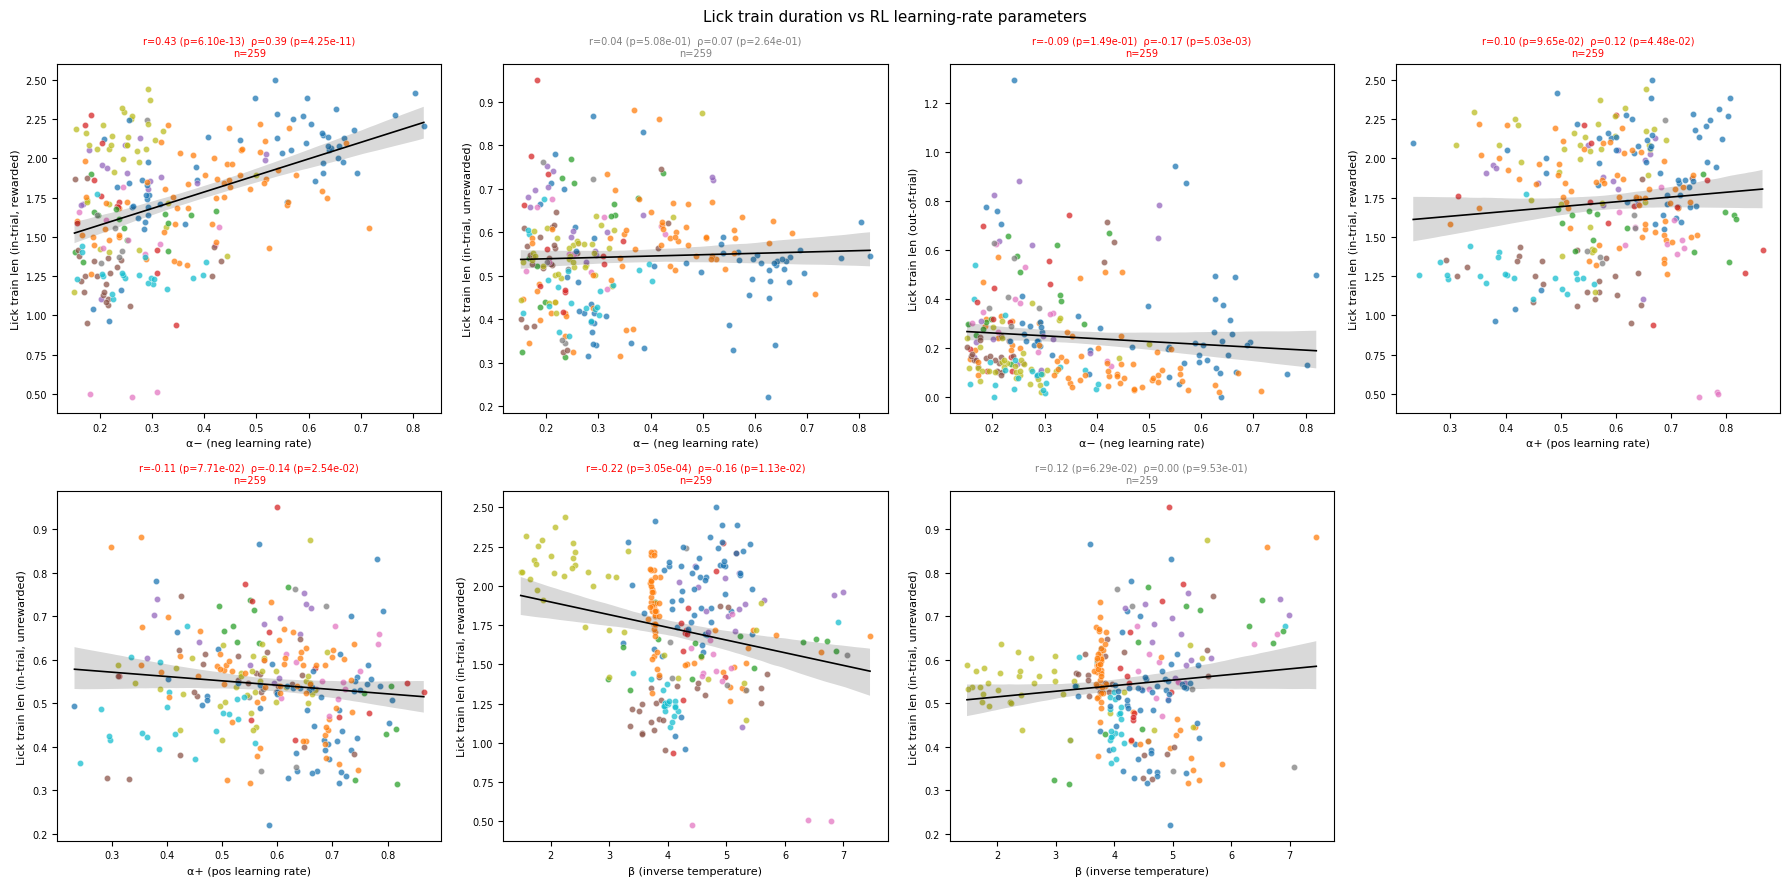

In [10]:
dur_pairs = [
    ('lick_len_in_rwd_mean',  'Lick train len (in-trial, rewarded)',   'aN', 'α− (neg learning rate)'),
    ('lick_len_in_nrwd_mean', 'Lick train len (in-trial, unrewarded)', 'aN', 'α− (neg learning rate)'),
    ('lick_len_out_mean',     'Lick train len (out-of-trial)',          'aN', 'α− (neg learning rate)'),
    ('lick_len_in_rwd_mean',  'Lick train len (in-trial, rewarded)',   'aP', 'α+ (pos learning rate)'),
    ('lick_len_in_nrwd_mean', 'Lick train len (in-trial, unrewarded)', 'aP', 'α+ (pos learning rate)'),
    ('lick_len_in_rwd_mean',  'Lick train len (in-trial, rewarded)',   'beta', 'β (inverse temperature)'),
    ('lick_len_in_nrwd_mean', 'Lick train len (in-trial, unrewarded)', 'beta', 'β (inverse temperature)'),
]

dur_pairs = [(y_c, y_l, x_c, x_l) for y_c, y_l, x_c, x_l in dur_pairs
             if y_c in merged_df.columns and x_c in merged_df.columns]

if dur_pairs:
    ncols = min(4, len(dur_pairs))
    nrows = int(np.ceil(len(dur_pairs) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 4.5 * nrows), squeeze=False)
    flat_axes = axes.flatten()
    for ax, (y_col, y_lbl, x_col, x_lbl) in zip(flat_axes, dur_pairs):
        scatter_lick_vs_beh(ax, merged_df, x_col, x_lbl, y_col, y_lbl)
    for ax in flat_axes[len(dur_pairs):]:
        ax.set_visible(False)

    plt.suptitle('Lick train duration vs RL learning-rate parameters', fontsize=11)
    plt.tight_layout()
    out_path = os.path.join(target_folder, 'lick_duration_vs_lr_params.pdf')
    fig.savefig(out_path, bbox_inches='tight', dpi=300)
    print(f'Saved: {out_path}')
    plt.show()

## In/out lick ratio vs switch probabilities

Animals that lick more during the trial (high `in_out_ratio`) may also be more  
likely to stay with a winning choice or switch after a loss.

Saved: /root/capsule/scratch/result/manuscript/figures/F_lick_beh_session_comparison/in_out_ratio_vs_switch_probs.pdf


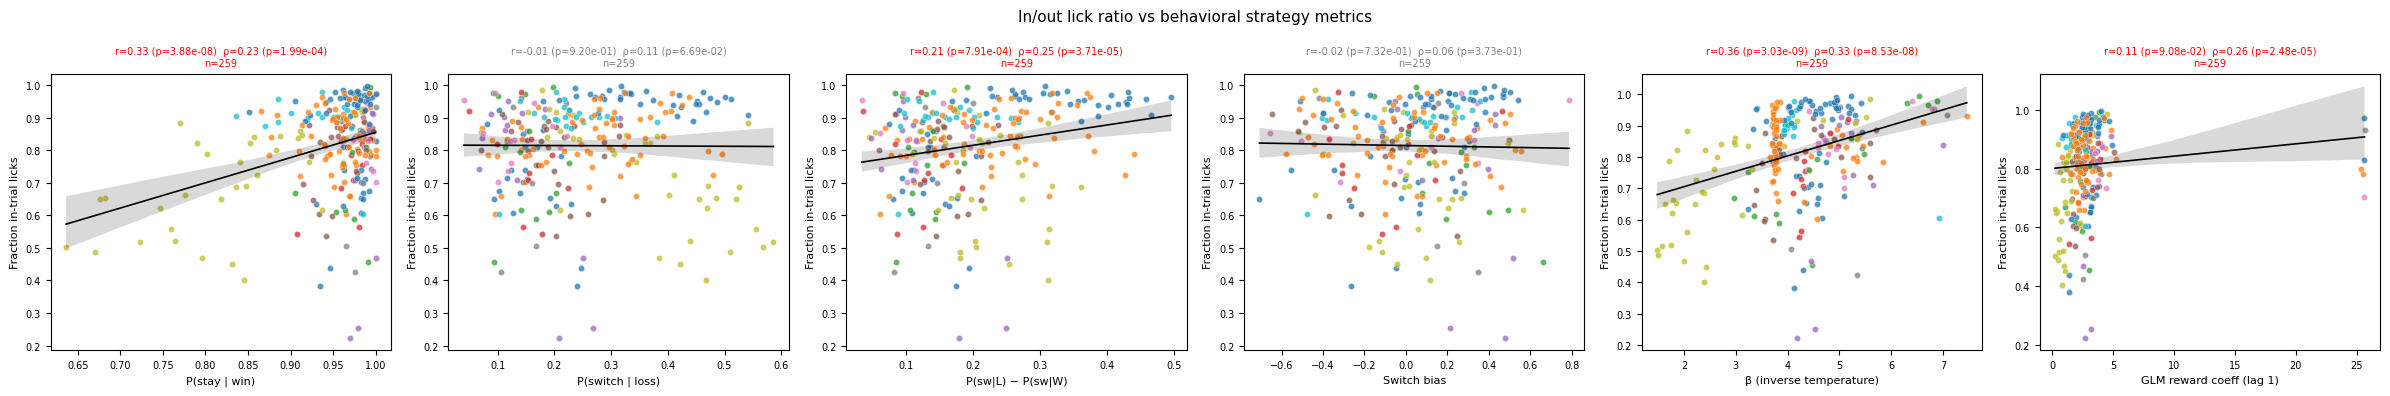

In [11]:
engagement_pairs = [
    ('in_out_ratio', 'Fraction in-trial licks', 'p_st_w',     'P(stay | win)'),
    ('in_out_ratio', 'Fraction in-trial licks', 'p_sw_L',     'P(switch | loss)'),
    ('in_out_ratio', 'Fraction in-trial licks', 'p_sw_L-W',   'P(sw|L) − P(sw|W)'),
    ('in_out_ratio', 'Fraction in-trial licks', 'sw_bias',    'Switch bias'),
    ('in_out_ratio', 'Fraction in-trial licks', 'beta',       'β (inverse temperature)'),
    ('in_out_ratio', 'Fraction in-trial licks', 'rwd_1',      'GLM reward coeff (lag 1)'),
]

engagement_pairs = [(y_c, y_l, x_c, x_l) for y_c, y_l, x_c, x_l in engagement_pairs
                    if y_c in merged_df.columns and x_c in merged_df.columns]

if engagement_pairs:
    fig, axes = plt.subplots(1, len(engagement_pairs), figsize=(4 * len(engagement_pairs), 4), squeeze=False)
    for ax, (y_col, y_lbl, x_col, x_lbl) in zip(axes[0], engagement_pairs):
        scatter_lick_vs_beh(ax, merged_df, x_col, x_lbl, y_col, y_lbl)

    plt.suptitle('In/out lick ratio vs behavioral strategy metrics', fontsize=11)
    plt.tight_layout()
    out_path = os.path.join(target_folder, 'in_out_ratio_vs_switch_probs.pdf')
    fig.savefig(out_path, bbox_inches='tight', dpi=300)
    print(f'Saved: {out_path}')
    plt.show()

## Animal color legend

Saved: /root/capsule/scratch/result/manuscript/figures/F_lick_beh_session_comparison/animal_color_legend.pdf


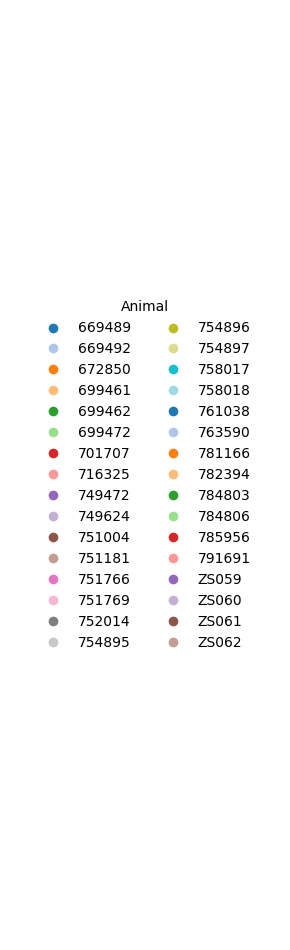

In [12]:
fig_leg, ax_leg = plt.subplots(figsize=(3, max(2, len(animals) * 0.3)))
handles = [
    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor=ANI_COLOR[ani], markersize=8, label=ani)
    for ani in animals
]
ax_leg.legend(handles=handles, title='Animal', loc='center', frameon=False, ncol=2)
ax_leg.axis('off')
plt.tight_layout()
out_path = os.path.join(target_folder, 'animal_color_legend.pdf')
fig_leg.savefig(out_path, bbox_inches='tight', dpi=150)
print(f'Saved: {out_path}')
plt.show()

## Correlation summary table

Rank all lick × behavior pairs by |Pearson r|, showing only significant ones (p < 0.05).

In [13]:
corr_rows = []
for lick_col, lick_lbl in LICK_COLS:
    for beh_col, beh_lbl in BEH_COLS:
        valid = merged_df[[lick_col, beh_col]].dropna()
        if len(valid) < 5:
            continue
        r_p, p_p = pearsonr(valid[lick_col], valid[beh_col])
        r_s, p_s = spearmanr(valid[lick_col], valid[beh_col])
        corr_rows.append({
            'lick_col'       : lick_col,
            'lick_label'     : lick_lbl,
            'beh_col'        : beh_col,
            'beh_label'      : beh_lbl,
            'pearson_r'      : r_p,
            'pearson_p'      : p_p,
            'spearman_rho'   : r_s,
            'spearman_p'     : p_s,
            'n'              : len(valid),
        })

corr_df = pd.DataFrame(corr_rows)
corr_df['abs_r'] = corr_df['pearson_r'].abs()
corr_df['sig_pearson']  = corr_df['pearson_p']  < 0.05
corr_df['sig_spearman'] = corr_df['spearman_p'] < 0.05
corr_df.sort_values('abs_r', ascending=False, inplace=True)

print('=== Significant correlations (Pearson p < 0.05) ===\n')
sig = corr_df[corr_df['sig_pearson']]
print(sig[['lick_label', 'beh_label', 'pearson_r', 'pearson_p', 'spearman_rho', 'spearman_p', 'n']]
      .to_string(index=False))

# Save full table
csv_path = os.path.join(target_folder, 'lick_beh_correlation_table.csv')
corr_df.to_csv(csv_path, index=False)
print(f'\nFull correlation table saved: {csv_path}')

=== Significant correlations (Pearson p < 0.05) ===

                                lick_label                   beh_label  pearson_r    pearson_p  spearman_rho   spearman_p   n
                          Choice R/L ratio                 Switch bias   0.775608 2.827408e-53      0.766672 2.259936e-51 259
                   In-trial lick R/L ratio                 Switch bias   0.687693 1.312880e-37      0.685476 2.760780e-37 259
                 Mean lick train len (all)      α− (neg learning rate)   0.624003 2.345943e-29      0.584871 3.648147e-25 259
     In-trial R/L ratio (rewarded choices)                 Switch bias   0.587880 1.818852e-25      0.572616 5.774534e-24 259
                 Mean lick train len (all)           P(sw|L) − P(sw|W)   0.511044 1.235331e-18      0.448901 3.016086e-14 259
                 Mean lick train len (all)  GLM sw: no-reward − reward   0.511044 1.235331e-18      0.448901 3.016086e-14 259
  Mean lick train len (in-trial, rewarded)            P(switch | 

## Heatmap of Pearson r across all lick × behavior pairs

Saved: /root/capsule/scratch/result/manuscript/figures/F_lick_beh_session_comparison/lick_beh_pearson_heatmap.pdf


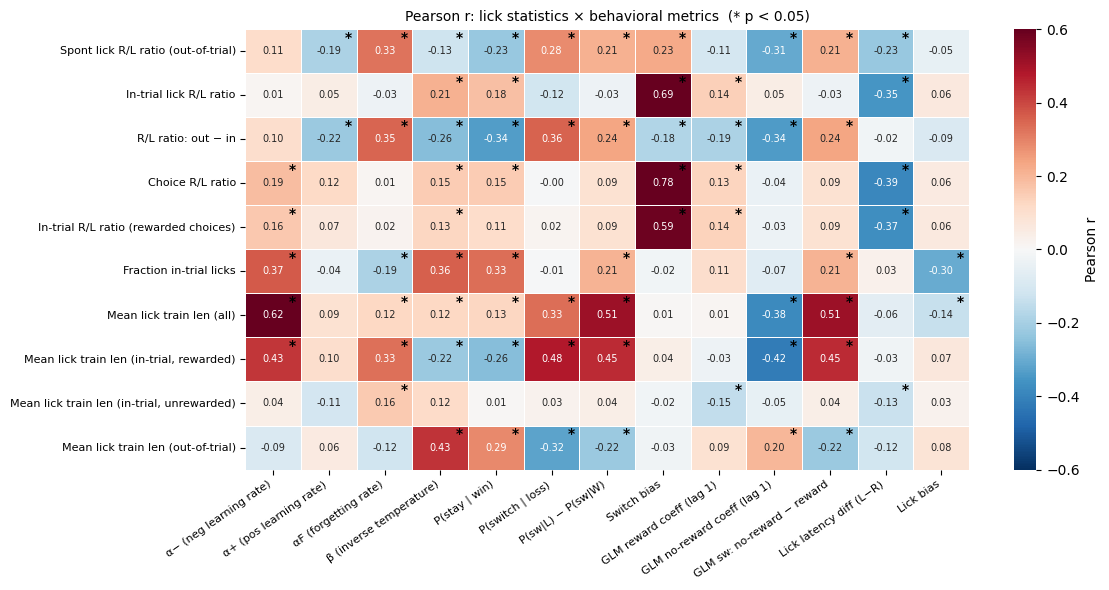

In [14]:
lick_labels = [lbl for _, lbl in LICK_COLS]
beh_labels  = [lbl for _, lbl in BEH_COLS]

r_mat  = np.full((len(LICK_COLS), len(BEH_COLS)), np.nan)
p_mat  = np.full((len(LICK_COLS), len(BEH_COLS)), np.nan)

for ri, (lick_col, _) in enumerate(LICK_COLS):
    for ci, (beh_col, _) in enumerate(BEH_COLS):
        valid = merged_df[[lick_col, beh_col]].dropna()
        if len(valid) >= 5:
            r, p = pearsonr(valid[lick_col], valid[beh_col])
            r_mat[ri, ci] = r
            p_mat[ri, ci] = p

fig, ax = plt.subplots(figsize=(max(8, 0.9 * len(BEH_COLS)), max(5, 0.6 * len(LICK_COLS))))
sns.heatmap(
    r_mat,
    ax=ax,
    xticklabels=beh_labels,
    yticklabels=lick_labels,
    cmap='RdBu_r',
    center=0,
    vmin=-0.6, vmax=0.6,
    annot=True, fmt='.2f',
    annot_kws={'size': 7},
    linewidths=0.5,
    cbar_kws={'label': 'Pearson r'},
)

# Mark significant cells with a star
for ri in range(len(LICK_COLS)):
    for ci in range(len(BEH_COLS)):
        if not np.isnan(p_mat[ri, ci]) and p_mat[ri, ci] < 0.05:
            ax.text(
                ci + 0.85, ri + 0.2, '*',
                ha='center', va='center',
                color='k', fontsize=10, fontweight='bold',
            )

ax.set_title('Pearson r: lick statistics × behavioral metrics  (* p < 0.05)', fontsize=10)
plt.xticks(rotation=35, ha='right', fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()

out_path = os.path.join(target_folder, 'lick_beh_pearson_heatmap.pdf')
fig.savefig(out_path, bbox_inches='tight', dpi=300)
print(f'Saved: {out_path}')
plt.show()